# DAMICORE v2 — EEG: Controle × CCL (MCI) × Alzheimer (AD)

Notebook construído passo a passo. Esta pasta é independente: os dados ficam em `dados/` e tudo o que é gerado vai para `saida/`.

**Passo 1 — Leitura e organização dos objetos**

1. Inventário dos pacientes, separados pelo estado: `AD`, `CONTROL` e `MCI`.
2. Leitura do sinal de cada paciente (valores originais, sem processamento).
3. Retirada dos pacientes com canal plano e separação por estado e, dentro de cada estado, por canal: `saida/objetos/<estado>/<canal>/<paciente>.bin`.

**Passo 2 — Primeira discretização com o DAMICORE (k=2), separada por estado**

4. DAMICORE em cada pasta de canal, uma execução por estado e canal: CONTROL (pacientes bons) e AD (pacientes ruins). MCI fica desligado por enquanto.
5. Tabela de discretização de cada estado: linhas = pacientes, colunas = canais, células = 0 ou 1.

**Passo 3 — DAMICORE sobre cada tabela: grupos de canais**

6. DAMICORE sobre a tabela de cada estado, com os canais (colunas) como objetos e número de grupos automático.
7. Todas as saídas do DAMICORE: arquivos, relatório, objetos lidos, matriz de distâncias, filograma e grupos de canais.

**Passo 4 — Tabelas de probabilidade dos grupos**

8. Subtabela de cada grupo (os canais do grupo nas colunas) e tabela de probabilidade: cada padrão de linha, sua contagem e probabilidade.

## 0. Configuração

| Parâmetro | Valor | Motivo |
|---|---|---|
| `N_AMOSTRAS` | 3840 | cada objeto tem 3840 valores `float32` (15 KB). O compressor do NCD (zlib) só enxerga repetições até 32 KB para trás, então um par de objetos precisa caber nisso. São 30 s nos registros a 128 Hz e 15 s nos de 256 Hz |
| `CANAIS` | 19 canais do sistema 10-20 | os arquivos não trazem os nomes; a ordem segue as tabelas do artigo do dataset |
| `ESTADOS` | `AD`, `CONTROL`, `MCI` | as três pastas do dataset |

Se a pasta `dados/` não existir, a célula baixa o dataset original do figshare (293 MB).

In [1]:
from pathlib import Path
import io, shutil, urllib.request, zipfile
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt

RAIZ = next((p for p in [Path.cwd(), Path.cwd() / 'DAMICORE_v2'] if (p / 'damicore_v2.ipynb').is_file()), Path.cwd())
DADOS = RAIZ / 'dados'
SAIDA = RAIZ / 'saida'

ESTADOS = ['AD', 'CONTROL', 'MCI']
CANAIS = ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T3', 'C3', 'Cz',
          'C4', 'T4', 'T5', 'P3', 'Pz', 'P4', 'T6', 'O1', 'O2']
N_AMOSTRAS = 3840
CORES = {'CONTROL': '#2a78d6', 'MCI': '#eb6834', 'AD': '#1baf7a'}

if not (DADOS / 'readme.txt').is_file():
    print('Baixando o dataset do figshare (doi:10.6084/m9.figshare.5450293)...')
    with urllib.request.urlopen('https://ndownloader.figshare.com/files/9423433') as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extractall(DADOS)
SAIDA.mkdir(exist_ok=True)
pd.set_option('display.width', 200)
print('Dados:', DADOS)
print('Saída:', SAIDA)

Dados: c:\DAMICORE\DAMICORE_v2\dados
Saída: c:\DAMICORE\DAMICORE_v2\saida


## 1. Inventário dos pacientes por estado

Cada estado tem sua pasta e seu formato de arquivo:

- **AD e MCI:** uma pasta por paciente, com vários segmentos `.mat` (variável `export`, amostras × canais).
  Segmentos com 17, 18 ou 20 colunas são ignorados, porque não dá para saber qual coluna é qual canal. AD33 e AD44 ficam sem nenhum segmento válido.
- **CONTROL:** 100 arquivos `*fir.mat` (variável `segmenty`, canais × amostras, valores inteiros; as 19 primeiras linhas são o EEG)
  e os pacientes `normal1` e `normal2`, no mesmo formato `export` de AD e MCI.

O `readme.txt` traz a frequência de amostragem e o escore cognitivo (0 a 100) de AD, MCI e dos dois `normal`.

In [2]:
def ler_readme(caminho):
    linhas = []
    for l in caminho.read_text(encoding='latin-1').splitlines():
        p = l.split('\t')
        if len(p) == 8 and p[7].strip() and p[0].strip().isdigit():
            linhas.append(dict(paciente=p[7].strip(), escore=int(p[5]), fs=int(p[6])))
    return pd.DataFrame(linhas).set_index('paciente')

def n_colunas(arquivo):
    return sio.loadmat(arquivo, variable_names=['export'])['export'].shape[1]

def segmentos(pasta):
    return sorted(pasta.glob('*.mat'), key=lambda f: int(f.stem))

readme = ler_readme(DADOS / 'readme.txt')
registros = []
for estado in ESTADOS:
    pasta_estado = DADOS / estado
    if estado == 'CONTROL':
        for f in sorted(pasta_estado.glob('*fir.mat')):
            registros.append(dict(paciente=f.stem, estado=estado, formato='fir', fs=128, arquivos=[f]))
        pastas = [pasta_estado / 'normal1', pasta_estado / 'normal2']
    else:
        pastas = sorted(pasta_estado.iterdir(), key=lambda p: int(p.name[len(estado):]))
    for pasta in pastas:
        arqs = [f for f in segmentos(pasta) if n_colunas(f) == 19]
        if arqs:
            registros.append(dict(paciente=pasta.name, estado=estado, formato='export',
                                  fs=int(readme.loc[pasta.name, 'fs']), arquivos=arqs))

pacientes = pd.DataFrame(registros).set_index('paciente').join(readme[['escore']])
pacientes['n_segmentos'] = pacientes.arquivos.str.len()
pacientes.drop(columns='arquivos').to_csv(SAIDA / 'pacientes.csv')
print(f'{len(pacientes)} pacientes com sinal de 19 canais')
pd.crosstab(pacientes.estado, [pacientes.formato, pacientes.fs], margins=True, margins_name='total').reindex(ESTADOS + ['total'])

166 pacientes com sinal de 19 canais


formato export      fir total
fs         128 256  128      
estado                       
AD          24  33    0    57
CONTROL      2   0  100   102
MCI          3   4    0     7
total       29  37  100   166

## 2. Leitura do sinal de cada paciente

O sinal de um paciente é a concatenação dos seus segmentos, com os valores originais (nenhum filtro, reamostragem ou normalização),
no formato amostras × 19 canais. Dele é recortada uma janela central de `N_AMOSTRAS` amostras.

A tabela mostra o primeiro paciente de cada estado.

In [3]:
def ler_sinal(p):
    """Sinal original do paciente: amostras x 19 canais, segmentos concatenados."""
    if p.formato == 'fir':
        partes = [sio.loadmat(p.arquivos[0])['segmenty'][:19].T]
    else:
        partes = [sio.loadmat(f)['export'] for f in p.arquivos]
    return np.concatenate(partes).astype(np.float32)

def janela_central(x, n=N_AMOSTRAS):
    ini = (len(x) - n) // 2
    return x[ini:ini + n]

exemplos = pacientes.groupby('estado').head(1)
resumo = []
for pid, p in exemplos.iterrows():
    x = ler_sinal(p)
    resumo.append(dict(paciente=pid, estado=p.estado, formato=p.formato, fs=p.fs,
                       amostras=x.shape[0], canais=x.shape[1], duracao_s=round(x.shape[0] / p.fs, 1),
                       primeiros_valores_Fp1=[round(float(v), 2) for v in x[:4, 0]]))
pd.DataFrame(resumo).set_index('paciente')

,estado,formato,fs,amostras,canais,duracao_s,primeiros_valores_Fp1
paciente,,,,,,,
AD1,AD,export,256,81040,19,316.6,"[-0.01, -0.01, 0.01, 0.01]"
10057fir,CONTROL,fir,128,12288,19,96.0,"[-5.0, -16.0, -28.0, -22.0]"
MCI1,MCI,export,256,46347,19,181.0,"[0.01, 0.0, -0.01, -0.0]"


## 3. Objetos: separados por estado e, dentro de cada estado, por canal

Cada canal da janela de cada paciente vira um arquivo binário com os valores `float32` originais:

```
saida/objetos/
├── AD/
│   ├── Fp1/   AD1.bin  AD2.bin  ...
│   ├── Fp2/
│   └── ...  (19 canais)
├── CONTROL/
│   └── ...
└── MCI/
    └── ...
```

**Decisão metodológica:** um paciente com algum canal plano (eletrodo sem sinal, todos os valores iguais na janela) é **retirado do estudo**,
em todos os canais. Dois objetos idênticos dariam NCD = 0, e deixar o paciente só nos outros canais deixaria uma célula vazia na tabela
de discretização. A retirada acontece antes de gerar os objetos, para que o paciente não influencie nenhuma execução do DAMICORE.
A lista final fica em `saida/pacientes.csv`, e os retirados em `saida/pacientes_retirados.csv`.

A pasta `objetos/` é regenerada a cada execução, para refletir os parâmetros atuais.

In [4]:
janelas = {pid: janela_central(ler_sinal(p)) for pid, p in pacientes.iterrows()}

retirados = pd.DataFrame([dict(paciente=pid, estado=pacientes.loc[pid, 'estado'], canal_plano=canal)
                          for pid, x in janelas.items() for i, canal in enumerate(CANAIS) if x[:, i].std() == 0],
                         columns=['paciente', 'estado', 'canal_plano'])
retirados.to_csv(SAIDA / 'pacientes_retirados.csv', index=False)
pacientes = pacientes.drop(index=retirados.paciente.unique())
pacientes.drop(columns='arquivos').to_csv(SAIDA / 'pacientes.csv')
print('Pacientes retirados (canal plano):')
display(retirados)
print('Pacientes no estudo:', pacientes.estado.value_counts().reindex(ESTADOS).to_dict())

Pacientes retirados (canal plano):


,paciente,estado,canal_plano
0,26887fir,CONTROL,Cz
1,7147fir,CONTROL,Cz


Pacientes no estudo: {'AD': 57, 'CONTROL': 100, 'MCI': 7}


In [5]:
DIR_OBJETOS = SAIDA / 'objetos'
if DIR_OBJETOS.exists():
    shutil.rmtree(DIR_OBJETOS)

for pid, p in pacientes.iterrows():
    for i, canal in enumerate(CANAIS):
        pasta = DIR_OBJETOS / p.estado / canal
        pasta.mkdir(parents=True, exist_ok=True)
        (pasta / f'{pid}.bin').write_bytes(np.ascontiguousarray(janelas[pid][:, i]).tobytes())

contagem = pd.DataFrame({estado: {canal: len(list((DIR_OBJETOS / estado / canal).glob('*.bin'))) for canal in CANAIS}
                         for estado in ESTADOS})
print(f'Objetos em {DIR_OBJETOS} ({N_AMOSTRAS * 4} bytes cada)')
print('Número de pacientes por estado (linhas) e canal (colunas):')
contagem.T

Objetos em c:\DAMICORE\DAMICORE_v2\saida\objetos (15360 bytes cada)
Número de pacientes por estado (linhas) e canal (colunas):


,Fp1,Fp2,F7,F3,Fz,F4,F8,T3,C3,Cz,C4,T4,T5,P3,Pz,P4,T6,O1,O2
AD,57,57,57,57,57,57,57,57,57,57,57,57,57,57,57,57,57,57,57
CONTROL,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100
MCI,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7,7


### 3.1 Um canal de um paciente de cada estado

Os primeiros 4 s do canal P3 na janela recortada, com os valores como chegam ao DAMICORE.
As escalas diferem entre formatos (os controles `fir` são inteiros), por isso cada painel tem o seu próprio eixo vertical.

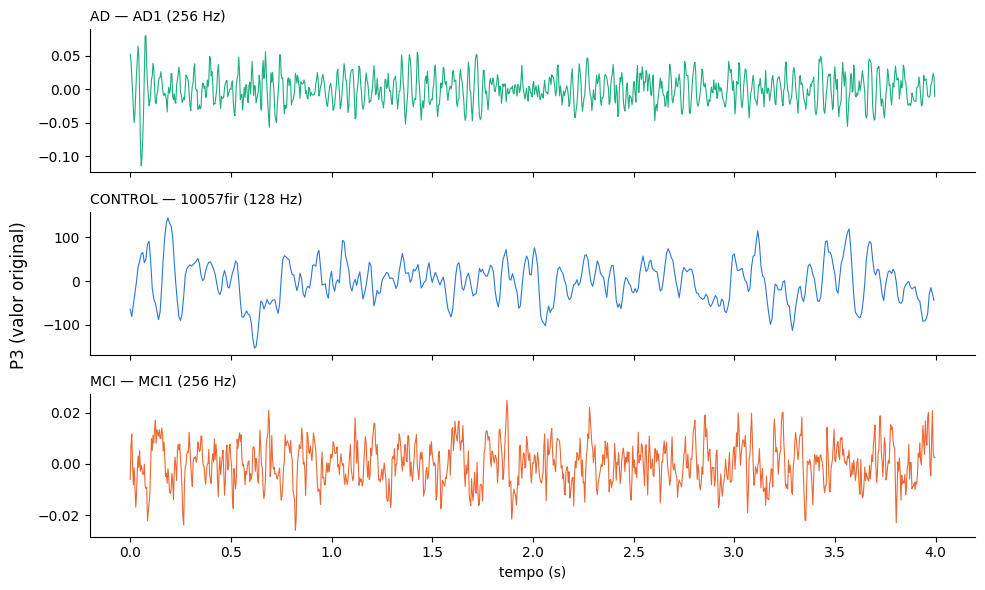

In [6]:
CANAL_EXEMPLO = 'P3'
i = CANAIS.index(CANAL_EXEMPLO)
fig, eixos = plt.subplots(len(ESTADOS), 1, figsize=(10, 6), sharex=True)
for ax, (pid, p) in zip(eixos, exemplos.iterrows()):
    t = np.arange(4 * p.fs) / p.fs
    ax.plot(t, janelas[pid][:len(t), i], color=CORES[p.estado], lw=0.8)
    ax.set_title(f'{p.estado} — {pid} ({p.fs} Hz)', loc='left', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
eixos[-1].set_xlabel('tempo (s)')
fig.supylabel(f'{CANAL_EXEMPLO} (valor original)')
fig.tight_layout()
plt.show()

## 4. Passo 2 — Discretização com o DAMICORE, separada por estado

Cada pasta `saida/objetos/<estado>/<canal>/` é a entrada de uma execução do DAMICORE (`source_kind='files'`): cada arquivo é um objeto (um paciente),
o NCD é calculado entre todos os pares, a árvore é montada por Neighbor Joining e o FastGreedy a divide em `K = 2` grupos.
O grupo de cada paciente (0 ou 1) é a discretização daquele canal.

Os estados são tratados em separado: CONTROL (pacientes bons) e AD (pacientes ruins) nunca entram juntos numa mesma execução.
`APLICAR_DAMICORE` liga ou desliga cada estado; MCI está desligado (`False`) nesta etapa e pode ser incluído depois trocando para `True`.

Se a pasta de saída de um canal já tiver uma execução com os mesmos objetos, ela é reaproveitada.

In [7]:
from damicore import run, ExecutionConfig, OutputDirectoryConflictError, DamicoreError

APLICAR_DAMICORE = {'CONTROL': True, 'AD': True, 'MCI': False}
K = 2

def damicore_canal(pasta, destino, k=K):
    # Roda o DAMICORE numa pasta de canal e devolve o grupo (0 ou 1) de cada paciente.
    args = dict(source_kind='files', num_clusters=k, output_dir=destino, progress=False,
                execution=ExecutionConfig(workers='auto'))
    for tentativa in range(3):
        try:
            r = run(pasta, **args)
            break
        except OutputDirectoryConflictError:      # objetos mudaram desde a última execução: refaz
            shutil.rmtree(destino)
        except DamicoreError as e:                # Windows: arquivo temporário bloqueado; retoma do checkpoint
            if 'PermissionError' not in str(e) or tentativa == 2:
                raise
    grupos = pd.Series(r.membership['cluster'].values,
                       index=r.membership['label'].str.removesuffix('.bin').values)
    r.close()
    return grupos

C:\Users\rodri\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
DIR_DAMICORE = SAIDA / 'damicore'
DIR_TABELAS = SAIDA / 'discretizacao'
DIR_TABELAS.mkdir(exist_ok=True)

tabelas = {}
for estado, aplicar in APLICAR_DAMICORE.items():
    if not aplicar:
        print(f'{estado}: DAMICORE desligado nesta etapa')
        continue
    colunas = {}
    for canal in CANAIS:
        colunas[canal] = damicore_canal(DIR_OBJETOS / estado / canal, DIR_DAMICORE / estado / f'k{K}' / canal)
        print(f'{estado:>7} {canal:>3}: grupos 0/1 = {colunas[canal].value_counts().sort_index().tolist()}')
    ordem = pacientes.index[pacientes.estado == estado]
    tabela = pd.DataFrame(colunas).reindex(ordem).astype(int)   # falha se faltar algum valor
    tabela.index.name = 'paciente'
    tabela.to_csv(DIR_TABELAS / f'tabela_{estado}_k{K}.csv')
    tabelas[estado] = tabela
    print(f'{estado}: tabela {tabela.shape[0]} pacientes x {tabela.shape[1]} canais -> {DIR_TABELAS / f"tabela_{estado}_k{K}.csv"}')
    print()

CONTROL Fp1: grupos 0/1 = [72, 28]


CONTROL Fp2: grupos 0/1 = [55, 45]


CONTROL  F7: grupos 0/1 = [62, 38]


CONTROL  F3: grupos 0/1 = [49, 51]


CONTROL  Fz: grupos 0/1 = [55, 45]


CONTROL  F4: grupos 0/1 = [41, 59]


... (18 outputs left out)

     AD  T4: grupos 0/1 = [23, 34]
     AD  T5: grupos 0/1 = [37, 20]


     AD  P3: grupos 0/1 = [25, 32]
     AD  Pz: grupos 0/1 = [35, 22]


     AD  P4: grupos 0/1 = [30, 27]
     AD  T6: grupos 0/1 = [36, 21]


     AD  O1: grupos 0/1 = [33, 24]
     AD  O2: grupos 0/1 = [29, 28]
AD: tabela 57 pacientes x 19 canais -> c:\DAMICORE\DAMICORE_v2\saida\discretizacao\tabela_AD_k2.csv

MCI: DAMICORE desligado nesta etapa


### 4.1 Tabelas de discretização

Uma tabela por estado: linhas = pacientes, colunas = canais, valor = grupo do paciente naquele canal.

**Atenção:** cada canal é uma execução independente, então o rótulo não tem o mesmo significado de um canal para outro
(o grupo 1 do Fp1 não corresponde ao grupo 1 do O2), nem de um estado para outro.

In [9]:
for estado, tabela in tabelas.items():
    print(f'{estado}: {tabela.shape[0]} pacientes x {tabela.shape[1]} canais')
    display(tabela.head(10))

CONTROL: 100 pacientes x 19 canais


,Fp1,Fp2,F7,F3,Fz,F4,F8,T3,C3,Cz,C4,T4,T5,P3,Pz,P4,T6,O1,O2
paciente,,,,,,,,,,,,,,,,,,,
10057fir,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
10188fir,0,0,0,0,1,0,0,0,1,1,1,0,0,0,0,0,0,0,0
10271fir,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,1,1,1,0
10600fir,1,0,0,0,1,0,1,1,1,1,0,1,0,0,1,1,0,0,0
1105fir,0,1,0,1,1,1,1,1,0,0,0,1,1,1,1,1,1,1,1
11066fir,1,0,0,0,1,0,1,1,1,1,0,1,0,0,1,1,1,1,1
1134fir,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0
11357fir,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0
11381fir,0,0,1,0,1,1,0,1,1,1,0,1,0,0,1,0,1,0,0


AD: 57 pacientes x 19 canais


,Fp1,Fp2,F7,F3,Fz,F4,F8,T3,C3,Cz,C4,T4,T5,P3,Pz,P4,T6,O1,O2
paciente,,,,,,,,,,,,,,,,,,,
AD1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
AD2,0,0,0,0,0,0,0,1,1,0,1,0,1,0,0,0,0,0,0
AD3,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
AD4,0,0,0,0,0,0,0,1,1,0,1,1,1,0,0,0,0,0,1
AD5,1,1,1,1,1,1,1,0,0,0,0,1,0,1,1,1,1,1,1
AD6,0,0,0,0,0,0,0,1,1,0,1,0,1,0,0,0,0,0,1
AD7,1,1,1,1,0,0,1,0,0,0,0,1,0,1,0,1,1,1,1
AD8,0,0,1,0,1,0,1,0,0,0,0,1,0,1,0,0,1,1,1
AD9,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0


In [10]:
# Quantos pacientes ficaram no grupo 0 e no grupo 1 em cada canal
pd.concat({estado: t.apply(lambda c: c.value_counts()).T.reindex(columns=[0, 1]) for estado, t in tabelas.items()},
          axis=1).fillna(0).astype(int)

CONTROL      AD    
          0   1   0   1
Fp1      72  28  37  20
Fp2      55  45  37  20
F7       62  38  26  31
F3       49  51  31  26
Fz       55  45  34  23
F4       41  59  37  20
F8       34  66  31  26
T3       45  55  29  28
C3       56  44  33  24
Cz       63  37  37  20
C4       62  38  36  21
T4       37  63  23  34
T5       63  37  37  20
P3       64  36  25  32
Pz       33  67  35  22
P4       32  68  30  27
T6       33  67  36  21
O1       54  46  33  24
O2       56  44  29  28

## 5. Passo 3 — DAMICORE sobre as tabelas de discretização: grupos de canais

A entrada agora é a tabela de cada estado (linhas = pacientes, colunas = canais, valores 0/1).
O DAMICORE roda uma vez por tabela, com **cada canal (coluna) como objeto**: o objeto de um canal é a sequência de 0/1 dos pacientes naquele canal
(100 valores no CONTROL, 57 no AD). O NCD compara essas sequências; a árvore NJ e o FastGreedy reúnem os canais que discretizaram os pacientes de modo parecido.

- `split='columns'`: cada coluna é um objeto. A coluna `paciente` é retirada antes; ela é só o rótulo das linhas.
- `num_clusters=None`: o FastGreedy escolhe o número de grupos pela modularidade.
- `keep_normalized=True` e `save_diagnostics=True`: o DAMICORE guarda também os objetos como ele os leu e a matriz de distâncias em CSV,
  para que todas as saídas possam ser inspecionadas.

Saídas em `saida/grupos_canais/<estado>/`: a tabela de entrada (`entrada.csv`) e os arquivos do DAMICORE (`damicore/`).

In [11]:
import json
from matplotlib.lines import Line2D
from sklearn.metrics import adjusted_rand_score

K_TABELAS = None                       # None = automático (FastGreedy escolhe o número de grupos)
DIR_GRUPOS = SAIDA / 'grupos_canais'

def damicore_tabela(estado, k=K_TABELAS):
    pasta = DIR_GRUPOS / estado
    pasta.mkdir(parents=True, exist_ok=True)
    entrada = pasta / 'entrada.csv'
    tabelas[estado].to_csv(entrada, index=False)          # só os canais: a coluna paciente não é objeto
    destino = pasta / 'damicore'
    args = dict(source_kind='delimited', split='columns', num_clusters=k, output_dir=destino,
                keep_normalized=True, save_diagnostics=True, progress=False)
    try:
        r = run(entrada, **args)
    except OutputDirectoryConflictError:                  # a tabela mudou desde a última execução: refaz
        shutil.rmtree(destino)
        r = run(entrada, **args)
    r.close()
    return destino

def carregar(destino):
    # Lê os arquivos de saída do DAMICORE de uma execução
    rotulos = json.loads((destino / 'labels.json').read_text(encoding='utf-8'))
    nomes = dict(zip(rotulos['object_ids'], rotulos['labels']))
    return dict(
        destino=destino,
        nomes=nomes,
        relatorio=json.loads((destino / 'report.json').read_text(encoding='utf-8')),
        distancia=pd.DataFrame(np.load(destino / 'distance.npy'), index=rotulos['labels'], columns=rotulos['labels']),
        grupos=pd.read_csv(destino / 'membership.csv').set_index('label')['cluster'],
        arvore=json.loads((destino / 'tree.json').read_text(encoding='utf-8')),
        newick=(destino / 'tree.nwk').read_text(encoding='utf-8'))

resultados = {}
for estado in tabelas:
    resultados[estado] = carregar(damicore_tabela(estado))
    g = resultados[estado]['grupos']
    print(f'{estado}: {g.nunique()} grupos de canais -> {resultados[estado]["destino"]}')

CONTROL: 6 grupos de canais -> c:\DAMICORE\DAMICORE_v2\saida\grupos_canais\CONTROL\damicore
AD: 7 grupos de canais -> c:\DAMICORE\DAMICORE_v2\saida\grupos_canais\AD\damicore


### 5.1 Arquivos que o DAMICORE gera

Cada execução deixa os mesmos arquivos. A tabela lista os de cada estado com o tamanho e o que contém.

In [12]:
DESCRICAO = {
    'labels.json': 'nome de cada objeto (canal) e o seu identificador interno (column_000001, ...)',
    'normalization/manifest.json': 'como a tabela foi lida: arquivo, separador, codificação, número de objetos',
    'normalization/objects/*.jsonl': 'um arquivo por objeto: a coluna como o DAMICORE a leu, um valor por linha',
    'checkpoints/compressed-sizes.json': 'tamanho comprimido de cada objeto, C(x), usado no NCD',
    'checkpoints/distance-shards.json': 'controle do cálculo da matriz em partes (permite retomar uma execução)',
    'distance.npy': 'matriz de distâncias NCD (objetos x objetos), formato NumPy',
    'diagnostics/distance.csv': 'a mesma matriz de distâncias, em CSV',
    'diagnostics/ncd-pairs.csv': 'o NCD de cada par de objetos, um par por linha',
    'tree.nwk': 'árvore do Neighbor Joining (filograma) no formato Newick',
    'tree.json': 'a mesma árvore: nós, arestas com comprimento e a raiz',
    'membership.csv': 'grupo de cada objeto (o resultado do FastGreedy)',
    'clusters.json': 'os mesmos grupos, listados por grupo',
    'report.json': 'resumo da execução: número de grupos, modularidade, faixa do NCD, tempos e verificações',
    'manifest.json': 'lista de todos os arquivos com tamanho e hash (sha256), para conferência',
}

def chave(rel):
    return 'normalization/objects/*.jsonl' if rel.startswith('normalization/objects/') else rel

linhas = []
for estado, res in resultados.items():
    arquivos = sorted(p for p in res['destino'].rglob('*') if p.is_file())
    for c in dict.fromkeys(chave(p.relative_to(res['destino']).as_posix()) for p in arquivos):
        grupo = [p for p in arquivos if chave(p.relative_to(res['destino']).as_posix()) == c]
        linhas.append(dict(estado=estado, arquivo=c, n_arquivos=len(grupo),
                           kb=round(sum(p.stat().st_size for p in grupo) / 1024, 1), conteudo=DESCRICAO.get(c, '')))
arquivos = pd.DataFrame(linhas)
arquivos['ordem'] = arquivos.arquivo.map({c: i for i, c in enumerate(DESCRICAO)})
with pd.option_context('display.max_colwidth', 120):
    display(arquivos.sort_values(['ordem', 'estado']).drop(columns='ordem').set_index(['arquivo', 'estado']))

n_arquivos    kb                                                                                 conteudo
arquivo                           estado                                                                                                            
labels.json                       AD                1   0.6           nome de cada objeto (canal) e o seu identificador interno (column_000001, ...)
                                  CONTROL           1   0.6           nome de cada objeto (canal) e o seu identificador interno (column_000001, ...)
normalization/manifest.json       AD                1   4.7               como a tabela foi lida: arquivo, separador, codificação, número de objetos
                                  CONTROL           1   4.7               como a tabela foi lida: arquivo, separador, codificação, número de objetos
normalization/objects/*.jsonl     AD               19   4.2                um arquivo por objeto: a coluna como o DAMICORE a leu, um valor por linha
                                  CONTROL          19   7.4                um arquivo por objeto: a coluna como o DAMICORE a leu, um valor por linha
checkpoints/compressed-sizes.json AD                1   1.1                                    tamanho comprimido de cada objeto, C(x), usado no NCD
                                  CONTROL           1   1.1                                    tamanho comprimido de cada objeto, C(x), usado no NCD
checkpoints/distance-shards.json  AD                1   1.1                   controle do cálculo da matriz em partes (permite retomar uma execução)
                                  CONTROL           1   1.1                   controle do cálculo da matriz em partes (permite retomar uma execução)
distance.npy                      AD                1   2.9                              matriz de distâncias NCD (objetos x objetos), formato NumPy
                                  CONTROL           1   2.9                              matriz de distâncias NCD (objetos x objetos), formato NumPy
diagnostics/distance.csv          AD                1   5.8                                                     a mesma matriz de distâncias, em CSV
                                  CONTROL           1   6.6                                                     a mesma matriz de distâncias, em CSV
diagnostics/ncd-pairs.csv         AD                1   8.1                                           o NCD de cada par de objetos, um par por linha
                                  CONTROL           1   8.5                                           o NCD de cada par de objetos, um par por linha
tree.nwk                          AD                1   1.2                                 árvore do Neighbor Joining (filograma) no formato Newick
                                  CONTROL           1   1.2                                 árvore do Neighbor Joining (filograma) no formato Newick
tree.json                         AD                1   7.0                                    a mesma árvore: nós, arestas com comprimento e a raiz
                                  CONTROL           1   7.0                                    a mesma árvore: nós, arestas com comprimento e a raiz
membership.csv                    AD                1   0.4                                         grupo de cada objeto (o resultado do FastGreedy)
                                  CONTROL           1   0.4                                         grupo de cada objeto (o resultado do FastGreedy)
clusters.json                     AD                1   1.4                                                     os mesmos grupos, listados por grupo
                                  CONTROL           1   1.3                                                     os mesmos grupos, listados por grupo
report.json                       AD                1   1.0  resumo da execução: número de grupos, modularidade, faixa do NCD, tempos e verificações
                    

### 5.2 Relatório da execução (`report.json`)

- `object_count`: número de objetos (19 canais) e `pair_count`: pares comparados (19 x 18 / 2 = 171).
- `ncd_min` / `ncd_max`: faixa das distâncias. O `ncd_min = 0` vem da diagonal (a distância de um canal com ele mesmo); os pares de canais diferentes estão na seção 5.4.
- `cluster_count`: número de grupos escolhido pelo FastGreedy; `modularidade`: quanto os grupos são mais ligados por dentro do que entre si (de 0 a 1).
- `negative_branch_count`: ramos de comprimento negativo na árvore NJ (o ideal é 0).

In [13]:
CAMPOS = ['object_count', 'pair_count', 'ncd_min', 'ncd_max', 'ncd_out_of_range_count', 'negative_branch_count',
          'cluster_count', 'modularity', 'status']
relatorio = pd.DataFrame({e: {c: r['relatorio'][c] for c in CAMPOS} for e, r in resultados.items()})
relatorio.loc['tempo_total_s'] = [round(r['relatorio']['timings_seconds']['total'], 2) for r in resultados.values()]
relatorio.loc['verificacoes_ok'] = [all(r['relatorio']['verification'].values()) for r in resultados.values()]
relatorio

,CONTROL,AD
object_count,19,19
pair_count,171,171
ncd_min,0.0,0.0
ncd_max,0.722222,0.72093
ncd_out_of_range_count,0,0
negative_branch_count,0,0
cluster_count,6,7
modularity,0.60049,0.630766
status,completed,completed
tempo_total_s,1.66,1.53


### 5.3 Objetos como o DAMICORE os leu (`normalization/objects/`)

Cada canal vira um arquivo com a sequência dos valores da coluna, um paciente por linha.
A tabela mostra os 10 primeiros valores de alguns canais, já com os nomes dos canais no lugar dos identificadores internos.

In [14]:
for estado, res in resultados.items():
    objetos = {}
    for oid, nome in res['nomes'].items():
        valores = (res['destino'] / 'normalization' / 'objects' / f'{oid}.jsonl').read_text(encoding='utf-8').split()
        objetos[nome] = [json.loads(v) for v in valores]
    vista = pd.DataFrame(objetos)
    vista.index = tabelas[estado].index
    iguais = (vista.astype(int) == tabelas[estado]).all().all()
    print(f'{estado}: {vista.shape[1]} objetos de {vista.shape[0]} valores; idênticos à tabela de discretização: {iguais}')
    display(vista[['Fp1', 'Fz', 'Cz', 'Pz', 'O1']].head(10).T)

CONTROL: 19 objetos de 100 valores; idênticos à tabela de discretização: True


paciente,10057fir,10188fir,10271fir,10600fir,1105fir,11066fir,1134fir,11357fir,11381fir,11467fir
Fp1,0,0,0,1,0,1,0,1,0,1
Fz,0,1,0,1,1,1,1,0,1,0
Cz,0,1,0,1,0,1,0,0,1,0
Pz,0,0,1,1,1,1,0,0,1,1
O1,0,0,1,0,1,1,0,0,0,1


AD: 19 objetos de 57 valores; idênticos à tabela de discretização: True


paciente,AD1,AD2,AD3,AD4,AD5,AD6,AD7,AD8,AD9,AD10
Fp1,0,0,0,0,1,0,1,0,0,1
Fz,0,0,0,0,1,0,0,1,0,1
Cz,0,0,0,0,0,0,0,0,0,1
Pz,0,0,0,0,1,0,0,0,0,1
O1,0,0,0,0,1,0,1,1,0,1


### 5.4 Matriz de distâncias NCD (`distance.npy`)

Distância entre cada par de canais: perto de 0 = os canais dividem os pacientes de forma parecida; perto de 1 = sem relação.
Os canais estão ordenados pelo grupo do DAMICORE, e as linhas finas separam os grupos.
O NCD não enxerga o rótulo 0/1 em si, só o padrão: dois canais com 0 e 1 trocados também ficam próximos.

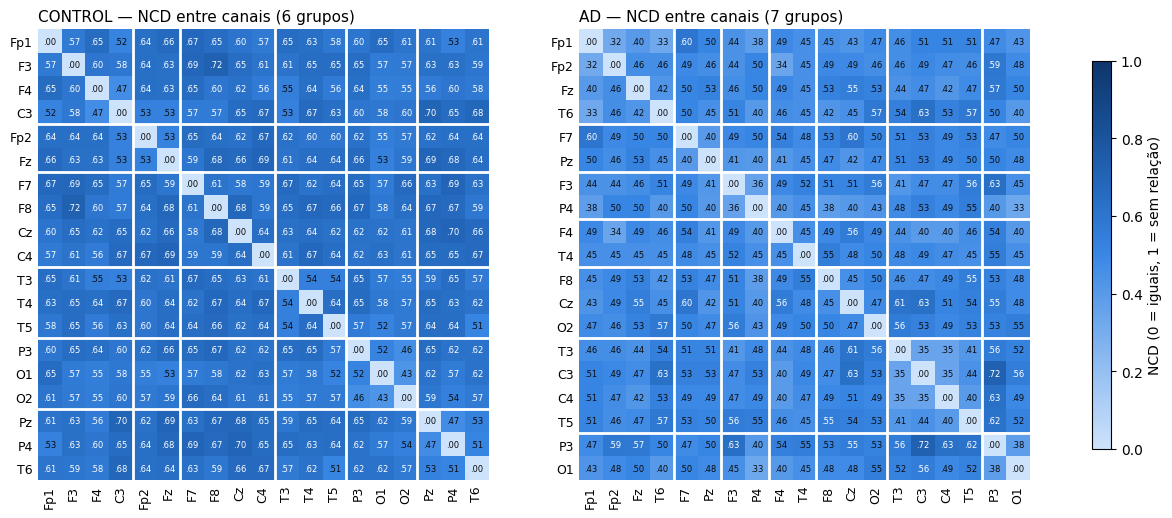

CONTROL: pares de canais com NCD = 0 (mesma discretização): nenhum
AD: pares de canais com NCD = 0 (mesma discretização): nenhum


In [15]:
RAMPA = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']   # sequencial: uma cor, claro -> escuro
from matplotlib.colors import LinearSegmentedColormap
CMAP_NCD = LinearSegmentedColormap.from_list('ncd', RAMPA)

def ordem_por_grupo(res):
    g = res['grupos']
    return sorted(g.index, key=lambda c: (g[c], CANAIS.index(c)))

fig, eixos = plt.subplots(1, len(resultados), figsize=(8 * len(resultados), 7.2))
eixos = np.atleast_1d(eixos)
for ax, (estado, res) in zip(eixos, resultados.items()):
    ordem = ordem_por_grupo(res)
    d = res['distancia'].loc[ordem, ordem]
    im = ax.imshow(d.values, cmap=CMAP_NCD, vmin=0, vmax=1)
    ax.set_xticks(range(len(ordem)), ordem, rotation=90, fontsize=9)
    ax.set_yticks(range(len(ordem)), ordem, fontsize=9)
    for i in range(len(ordem)):
        for j in range(len(ordem)):
            v = d.values[i, j]
            ax.text(j, i, f'{v:.2f}'[1:] if v < 1 else '1', ha='center', va='center', fontsize=6,
                    color='#0b0b0b' if v < 0.55 else '#ffffff')
    cortes = np.flatnonzero(np.diff(res['grupos'][ordem].values)) + 0.5
    for c in cortes:
        ax.axhline(c, color='#ffffff', lw=2)
        ax.axvline(c, color='#ffffff', lw=2)
    ax.set_title(f'{estado} — NCD entre canais ({res["grupos"].nunique()} grupos)', loc='left', fontsize=11)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.colorbar(im, ax=eixos.tolist(), shrink=0.7, label='NCD (0 = iguais, 1 = sem relação)')
plt.show()

for estado, res in resultados.items():
    d = res['distancia']
    iguais = [(a, b) for i, a in enumerate(d.index) for b in d.index[i + 1:] if d.loc[a, b] == 0]
    print(f'{estado}: pares de canais com NCD = 0 (mesma discretização): {iguais or "nenhum"}')

### 5.5 Filograma (`tree.nwk` / `tree.json`)

A árvore do Neighbor Joining desenhada a partir da raiz gravada pelo DAMICORE (`nj_root`, o último ponto de junção do algoritmo;
a árvore NJ em si não tem raiz). O comprimento horizontal de cada ramo é o comprimento da aresta: canais ligados por ramos curtos são próximos.
O ponto colorido ao lado de cada canal é o grupo do FastGreedy. Abaixo de cada árvore está o texto Newick.

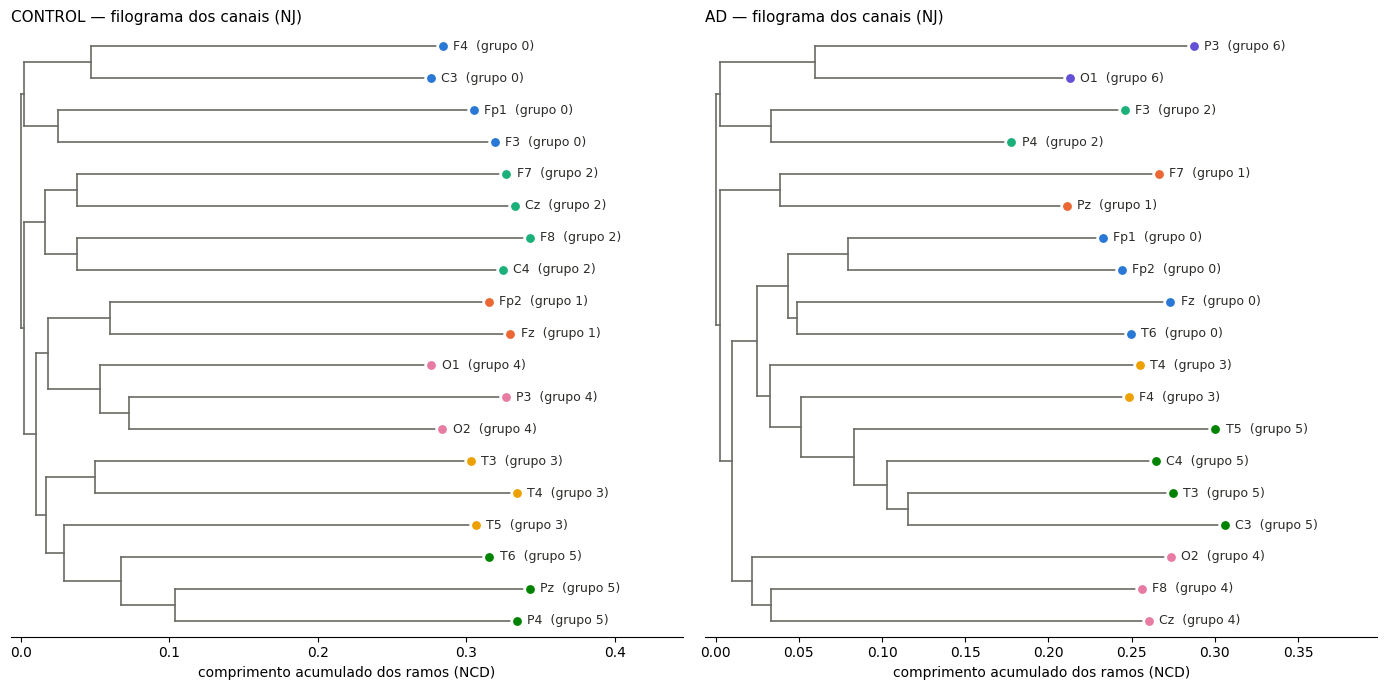

CONTROL (Newick, com o nome dos canais no lugar dos identificadores column_...):
(((F4:0.23740946301478985,C3:0.22925720365187682)'nj_000004':0.045101899304979674,(Fp1:0.28014731009004745,F3:0.2939267639840266)'nj_000010':0.023164093961013633)'nj_000016':0.0018606367224108496,(((F7:0.2895631458659314,Cz:0.29534251451142707)'nj_000008':0.021233341364395874,(F8:0.3048705400908357,C4:0.28696619460304185)'nj_000009':0.021604548508534428)'nj_000012':0.014326949811032932,(((Fp2:0.2555852339750645,Fz:0.26983849483849487)'nj_000005':0.041267480547566265,(O1:0.22318063818474393,(P3:0.2534295108194063,O2:0.210856203466308)'nj_000002':0.019676504672398953)'nj_000006':0.03483494809723525)'nj_000013':0.008380356301991668,((T3:0.25296142504102137,T4:0.2840756119960157)'nj_000007':0.03305995248585274,(T5:0.27733815829214364,(T6:0.24827275627920403,(Pz:0.23895152557892424,P4:0.2304362295231166)'nj_000001':0.036641209307030354)'nj_000003':0.03832961825243647)'nj_000011':0.012079776321328908)'nj_000014'

In [16]:
CORES_GRUPO = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']   # ordem fixa

def cor_grupo(g):
    return CORES_GRUPO[g % len(CORES_GRUPO)]

def desenhar_filograma(ax, res, titulo):
    arv = res['arvore']
    filhos, comp = {}, {}
    for e in arv['edges']:
        filhos.setdefault(e['source'], []).append(e['target'])
        comp[e['target']] = e['length']
    rotulo = {n['id']: n.get('label') for n in arv['nodes']}
    x, y, folhas = {}, {}, []

    def posicionar(no, x0):
        x[no] = x0
        if no not in filhos:                       # folha
            y[no] = len(folhas)
            folhas.append(no)
            return
        for f in filhos[no]:
            posicionar(f, x0 + comp[f])
        y[no] = np.mean([y[f] for f in filhos[no]])

    posicionar(arv['root_id'], 0.0)
    for no, fs in filhos.items():
        ax.plot([x[no], x[no]], [min(y[f] for f in fs), max(y[f] for f in fs)], color='#6b6a63', lw=1.2)
        for f in fs:
            ax.plot([x[no], x[f]], [y[f], y[f]], color='#6b6a63', lw=1.2)
    xmax = max(x.values())
    for f in folhas:
        nome = rotulo[f]
        g = res['grupos'][nome]
        ax.scatter(x[f], y[f], s=70, color=cor_grupo(g), edgecolor='white', linewidth=2, zorder=3)
        ax.text(x[f] + xmax * 0.02, y[f], f'{nome}  (grupo {g})', va='center', fontsize=9, color='#2b2b28')
    ax.set_xlim(-xmax * 0.02, xmax * 1.3)
    ax.set_ylim(len(folhas) - 0.5, -0.5)
    ax.set_yticks([])
    ax.set_xlabel('comprimento acumulado dos ramos (NCD)')
    ax.set_title(titulo, loc='left', fontsize=11)
    ax.spines[['top', 'right', 'left']].set_visible(False)

fig, eixos = plt.subplots(1, len(resultados), figsize=(7 * len(resultados), 7))
for ax, (estado, res) in zip(np.atleast_1d(eixos), resultados.items()):
    desenhar_filograma(ax, res, f'{estado} — filograma dos canais (NJ)')
fig.tight_layout()
plt.show()

import re
for estado, res in resultados.items():
    print(f'{estado} (Newick, com o nome dos canais no lugar dos identificadores column_...):')
    print(re.sub(r"'(column_\d+)'", lambda m: res['nomes'][m.group(1)], res['newick']))
    print()

### 5.6 Grupos de canais (`membership.csv` / `clusters.json`)

Os grupos de cada estado, primeiro como lista e depois na posição dos eletrodos no escalpo (sistema 10-20, vista de cima, nariz para cima).
Cada estado é uma execução independente, então o número de um grupo no CONTROL não corresponde ao mesmo número no AD: o que se compara são
**quais canais ficam juntos**.

In [17]:
for estado, res in resultados.items():
    g = res['grupos']
    lista = (g.groupby(g).apply(lambda s: ', '.join(sorted(s.index, key=CANAIS.index)))
              .rename('canais').to_frame())
    lista.insert(0, 'n_canais', g.value_counts().sort_index())
    lista.index.name = 'grupo'
    print(f'{estado}: {g.nunique()} grupos, modularidade {res["relatorio"]["modularity"]:.3f}')
    with pd.option_context('display.max_colwidth', 100):
        display(lista)

CONTROL: 6 grupos, modularidade 0.600


,n_canais,canais
grupo,,
0,4,"Fp1, F3, F4, C3"
1,2,"Fp2, Fz"
2,4,"F7, F8, Cz, C4"
3,3,"T3, T4, T5"
4,3,"P3, O1, O2"
5,3,"Pz, P4, T6"


AD: 7 grupos, modularidade 0.631


,n_canais,canais
grupo,,
0,4,"Fp1, Fp2, Fz, T6"
1,2,"F7, Pz"
2,2,"F3, P4"
3,2,"F4, T4"
4,3,"F8, Cz, O2"
5,4,"T3, C3, C4, T5"
6,2,"P3, O1"


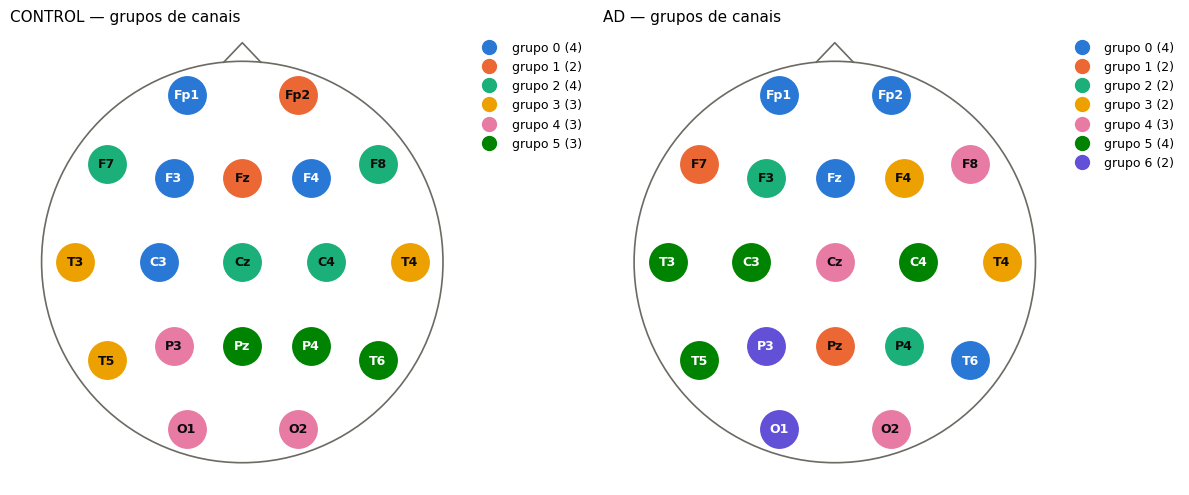

In [18]:
POSICOES = {'Fp1': (-0.3, 0.9), 'Fp2': (0.3, 0.9), 'F7': (-0.73, 0.53), 'F3': (-0.37, 0.45), 'Fz': (0, 0.45),
            'F4': (0.37, 0.45), 'F8': (0.73, 0.53), 'T3': (-0.9, 0), 'C3': (-0.45, 0), 'Cz': (0, 0), 'C4': (0.45, 0),
            'T4': (0.9, 0), 'T5': (-0.73, -0.53), 'P3': (-0.37, -0.45), 'Pz': (0, -0.45), 'P4': (0.37, -0.45),
            'T6': (0.73, -0.53), 'O1': (-0.3, -0.9), 'O2': (0.3, -0.9)}

fig, eixos = plt.subplots(1, len(resultados), figsize=(6 * len(resultados), 6.4))
for ax, (estado, res) in zip(np.atleast_1d(eixos), resultados.items()):
    g = res['grupos']
    ax.add_patch(plt.Circle((0, 0), 1.08, fill=False, color='#6b6a63', lw=1.2))
    ax.plot([-0.1, 0, 0.1], [1.075, 1.18, 1.075], color='#6b6a63', lw=1.2)          # nariz
    for canal, (px, py) in POSICOES.items():
        ax.scatter(px, py, s=900, color=cor_grupo(g[canal]), edgecolor='white', linewidth=2, zorder=3)
        tinta = '#0b0b0b' if cor_grupo(g[canal]) in ('#eb6834', '#1baf7a', '#eda100', '#e87ba4') else '#ffffff'
        ax.text(px, py, canal, ha='center', va='center', fontsize=9, color=tinta, fontweight='bold', zorder=4)
    alcas = [Line2D([], [], marker='o', ls='', markersize=10, color=cor_grupo(k), label=f'grupo {k} ({(g == k).sum()})')
             for k in sorted(g.unique())]
    ax.legend(handles=alcas, loc='upper left', bbox_to_anchor=(0.98, 1), frameon=False, fontsize=9)
    ax.set_title(f'{estado} — grupos de canais', loc='left', fontsize=11)
    ax.set_xlim(-1.25, 1.25); ax.set_ylim(-1.2, 1.25); ax.set_aspect('equal'); ax.axis('off')
fig.tight_layout()
plt.show()

### 5.7 CONTROL × AD: os canais ficam juntos do mesmo jeito?

Lado a lado, o grupo de cada canal nos dois estados. O ARI (índice de Rand ajustado) compara as duas partições sem depender dos números dos grupos:
1 = os mesmos canais juntos nos dois estados, 0 = nenhuma relação além do acaso.
A segunda tabela conta, para cada par de grupos, quantos canais estão no grupo do CONTROL (linha) e no grupo do AD (coluna).

In [19]:
if {'CONTROL', 'AD'} <= set(resultados):
    lado_a_lado = pd.DataFrame({e: resultados[e]['grupos'].reindex(CANAIS) for e in ['CONTROL', 'AD']})
    lado_a_lado.index.name = 'canal'
    print(f"ARI entre os grupos de canais do CONTROL e do AD: {adjusted_rand_score(lado_a_lado.CONTROL, lado_a_lado.AD):.3f}")
    display(lado_a_lado.T)
    display(pd.crosstab(lado_a_lado.CONTROL, lado_a_lado.AD, rownames=['grupo CONTROL'], colnames=['grupo AD']))

ARI entre os grupos de canais do CONTROL e do AD: 0.086


canal,Fp1,Fp2,F7,F3,Fz,F4,F8,T3,C3,Cz,C4,T4,T5,P3,Pz,P4,T6,O1,O2
CONTROL,0,1,2,0,1,0,2,3,0,2,2,3,3,4,5,5,5,4,4
AD,0,0,1,2,0,3,4,5,5,4,5,3,5,6,1,2,0,6,4


grupo AD,0,1,2,3,4,5,6
grupo CONTROL,,,,,,,
0,1,0,1,1,0,1,0
1,2,0,0,0,0,0,0
2,0,1,0,0,2,1,0
3,0,0,0,1,0,2,0
4,0,0,0,0,1,0,2
5,1,1,1,0,0,0,0


## 6. Passo 4 — Tabelas de probabilidade dos grupos de canais

**6.1 Os grupos em tabela.** A tabela de discretização de cada estado tem os 19 canais nas colunas, e o passo 3 disse a qual grupo cada canal pertence.
Para cada grupo, a **subtabela** é a tabela de discretização restrita às colunas dos canais daquele grupo: as mesmas linhas (pacientes), só os canais do grupo.

**6.2 Tabela de probabilidade.** Cada linha da subtabela é um **padrão** de 0/1 nos canais do grupo. A tabela de probabilidade lista cada padrão distinto
que aparece e a sua `probabilidade` = número de linhas com esse padrão / número total de linhas (pacientes). As probabilidades somam 1.
Padrões que não aparecem em nenhum paciente não entram na tabela.

Saídas em `saida/probabilidades/<estado>/grupo<g>_subtabela.csv` e `grupo<g>_probabilidade.csv`.

In [20]:
DIR_PROB = SAIDA / 'probabilidades'

def subtabela(estado, grupo):
    # Tabela de discretização do estado, só com as colunas (canais) do grupo
    g = resultados[estado]['grupos']
    canais = sorted(g.index[g == grupo], key=CANAIS.index)
    return tabelas[estado][canais]

def tabela_probabilidade(sub):
    # Um padrão por linha distinta da subtabela, com a sua probabilidade (contagem / total de linhas)
    canais = list(sub.columns)
    prob = sub.value_counts().rename('probabilidade').reset_index()
    prob['probabilidade'] = prob.probabilidade / len(sub)
    prob = prob.sort_values(['probabilidade'] + canais, ascending=[False] + [True] * len(canais), ignore_index=True)
    prob.index.name = 'padrao'
    return prob

subtabelas, probabilidades, resumo = {}, {}, []
for estado, res in resultados.items():
    (DIR_PROB / estado).mkdir(parents=True, exist_ok=True)
    for grupo in sorted(res['grupos'].unique()):
        sub = subtabela(estado, grupo)
        prob = tabela_probabilidade(sub)
        sub.to_csv(DIR_PROB / estado / f'grupo{grupo}_subtabela.csv')
        prob.to_csv(DIR_PROB / estado / f'grupo{grupo}_probabilidade.csv')
        subtabelas[estado, grupo], probabilidades[estado, grupo] = sub, prob
        resumo.append(dict(estado=estado, grupo=grupo, canais=', '.join(sub.columns), linhas=len(sub),
                           padroes_distintos=len(prob), padroes_possiveis=2 ** sub.shape[1],
                           prob_mais_comum=prob.probabilidade.iloc[0], soma_prob=round(prob.probabilidade.sum(), 6)))
resumo = pd.DataFrame(resumo).set_index(['estado', 'grupo'])
print(f'{len(probabilidades)} tabelas de probabilidade em {DIR_PROB}')
resumo

13 tabelas de probabilidade em c:\DAMICORE\DAMICORE_v2\saida\probabilidades


canais  linhas  padroes_distintos  padroes_possiveis  prob_mais_comum  soma_prob
estado  grupo                                                                                            
CONTROL 0       Fp1, F3, F4, C3     100                 16                 16         0.270000        1.0
        1               Fp2, Fz     100                  4                  4         0.280000        1.0
        2        F7, F8, Cz, C4     100                 16                 16         0.330000        1.0
        3            T3, T4, T5     100                  6                  8         0.350000        1.0
        4            P3, O1, O2     100                  8                  8         0.470000        1.0
        5            Pz, P4, T6     100                  8                  8         0.550000        1.0
AD      0      Fp1, Fp2, Fz, T6      57                  9                 16         0.543860        1.0
        1                F7, Pz      57                  4                  4         0.403509        1.0
        2                F3, P4      57                  4                  4         0.473684        1.0
        3                F4, T4      57                  4                  4         0.368421        1.0
        4            F8, Cz, O2      57                  7                  8         0.421053        1.0
        5        T3, C3, C4, T5      57                  9                 16         0.473684        1.0
        6                P3, O1      57                  3                  4         0.438596        1.0

### 6.3 Subtabela e tabela de probabilidade de cada grupo

Para cada grupo: as primeiras linhas da subtabela (pacientes x canais do grupo) e a tabela de probabilidade completa, do padrão mais comum para o menos comum.

In [21]:
for (estado, grupo), prob in probabilidades.items():
    sub = subtabelas[estado, grupo]
    print(f'=== {estado} — grupo {grupo}: canais {list(sub.columns)} | {len(sub)} linhas | '
          f'{len(prob)} de {2 ** sub.shape[1]} padrões possíveis aparecem')
    display(sub.head(5))
    display(prob.style.format({'probabilidade': '{:.4f}'}))

=== CONTROL — grupo 0: canais ['Fp1', 'F3', 'F4', 'C3'] | 100 linhas | 16 de 16 padrões possíveis aparecem


,Fp1,F3,F4,C3
paciente,,,,
10057fir,0,0,0,0
10188fir,0,0,0,1
10271fir,0,0,0,1
10600fir,1,0,0,1
1105fir,0,1,1,0


,Fp1,F3,F4,C3,probabilidade
padrao,,,,,
0,0,1,1,0,0.2700
1,0,0,0,1,0.1300
2,1,0,0,1,0.1000
3,0,0,0,0,0.0700
4,0,0,1,0,0.0600
5,0,0,1,1,0.0600
6,0,1,1,1,0.0600
7,1,1,1,0,0.0600
8,0,1,0,0,0.0400


=== CONTROL — grupo 1: canais ['Fp2', 'Fz'] | 100 linhas | 4 de 4 padrões possíveis aparecem


,Fp2,Fz
paciente,,
10057fir,0,0
10188fir,0,1
10271fir,0,0
10600fir,0,1
1105fir,1,1


,Fp2,Fz,probabilidade
padrao,,,
0,0,0,0.2800
1,0,1,0.2700
2,1,0,0.2700
3,1,1,0.1800


... (29 outputs left out)

,T3,C3,C4,T5,probabilidade
padrao,,,,,
0,0,0,0,0,0.4737
1,1,1,1,1,0.2982
2,1,0,0,0,0.0526
3,1,1,1,0,0.0526
4,1,0,0,1,0.0351
5,1,1,0,0,0.0351
6,0,1,0,0,0.0175
7,0,1,0,1,0.0175
8,1,0,1,0,0.0175


=== AD — grupo 6: canais ['P3', 'O1'] | 57 linhas | 3 de 4 padrões possíveis aparecem


,P3,O1
paciente,,
AD1,0,0
AD2,0,0
AD3,0,0
AD4,0,0
AD5,1,1


,P3,O1,probabilidade
padrao,,,
0,0,0,0.4386
1,1,1,0.4211
2,1,0,0.1404
